# Faster R-CNN trên VisDrone · Colab

**Luồng hoàn chỉnh cho detector:** ZIP trên Drive → DET COCO → kiểm tra nhãn → fine-tune
Faster R-CNN R50-FPN v2 → checkpoint tốt nhất trên DET val → biểu đồ + ảnh dự đoán → cache MOT val.
Có nhánh đánh giá DET test-dev riêng. DET/MOT test-dev chỉ chạy khi bật tùy chọn sau khi chốt mô hình.

**Chỉ cần tải file notebook này lên Colab; không cần clone GitHub hay tải các file Python kèm theo.**
Notebook chứa bản chụp công cụ tiền xử lý của nhóm và danh sách loại 57 ảnh DET train.

## Chuẩn bị
1. Chọn **Runtime → Change runtime type → GPU**.
2. Đặt ZIP gốc trong `MyDrive/AdvanceCV/datasets/`, đúng tên bên dưới.
3. Chạy các ô theo thứ tự hoặc **Run all**, cấp quyền mount Drive khi được hỏi.
4. Đọc ảnh GT ở bước 5; nếu nhãn sai thì dừng trước ô train.

```text
MyDrive/AdvanceCV/
├── datasets/
│   ├── VisDrone2019-DET-train.zip       # bắt buộc
│   ├── VisDrone2019-DET-val.zip         # bắt buộc
│   ├── VisDrone2019-DET-test-dev.zip    # đánh giá detection cuối trên DET
│   ├── VisDrone2019-MOT-val.zip         # cần để xuất cache tracking
│   └── VisDrone2019-MOT-test-dev.zip    # chỉ dùng khi chốt cấu hình
└── runs/                              # notebook tự tạo
```

Mỗi ZIP giữ cấu trúc gốc: `VisDrone2019-DET-*/images,annotations` hoặc
`VisDrone2019-MOT-*/sequences,annotations`. Không cần MOT train. ZIP lồng thêm thư mục
ngoài cấu trúc trên sẽ được báo lỗi. Ảnh giải nén vào `/content`, kết quả lưu trên Drive.

**Phạm vi:** notebook hoàn tất phần train/suy luận detector. Nó chưa tích hợp 5 tracker,
TrackEval, HOTA/IDF1, confusion matrix hay video tracking; cache xuất ra dùng làm đầu vào
cho công cụ chung đó. Các ảnh xem thử DET val không thay thế danh sách frame V0 của nhóm.


In [24]:
#@title 1. Kết nối Drive và chọn nơi lưu
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import json, sys, os, subprocess, importlib.util

DRIVE_ROOT = Path('/content/drive/MyDrive/AdvanceCV')
DATASETS = DRIVE_ROOT / 'datasets'
ROOT = Path('/content/thi_frcnn_visdrone')
RAW = ROOT / 'data/raw'
RUN_NAME = 'T2_frcnn_r50_v2_det_seed0' #@param {type:"string"}
EXPORT_MOT_VAL = True #@param {type:"boolean"}
EVALUATE_DET_TEST_DEV = True #@param {type:"boolean"}
EXPORT_MOT_TEST_DEV = True #@param {type:"boolean"}
# Bật test-dev chỉ sau khi đã chốt checkpoint / quy trình đánh giá.
assert RUN_NAME and Path(RUN_NAME).name == RUN_NAME and RUN_NAME not in ('.', '..')
RUN_DIR = DRIVE_ROOT / 'runs' / RUN_NAME
ROOT.mkdir(parents=True, exist_ok=True)
RUN_DIR.mkdir(parents=True, exist_ok=True)
assert DATASETS.is_dir(), f'Tạo thư mục {DATASETS} và tải ZIP vào đó trước.'
print('ZIP:', DATASETS)
print('Kết quả:', RUN_DIR)
print('ZIP hiện có:', [p.name for p in DATASETS.glob('*.zip')])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ZIP: /content/drive/MyDrive/AdvanceCV/datasets
Kết quả: /content/drive/MyDrive/AdvanceCV/runs/T2_frcnn_r50_v2_det_seed0
ZIP hiện có: ['VisDrone2019-MOT-val.zip', 'VisDrone2019-MOT-test-dev.zip', 'VisDrone2019-DET-train.zip', 'VisDrone2019-DET-val.zip', 'VisDrone2019-DET-test-dev.zip']


In [2]:
#@title 2. Kiểm tra GPU và thư viện
# Giữ nguyên cặp torch/torchvision có sẵn của Colab.
required = {'pycocotools': 'pycocotools', 'PIL': 'pillow', 'numpy': 'numpy',
            'matplotlib': 'matplotlib', 'tqdm': 'tqdm'}
missing = [package for module, package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', *missing], check=True)

import torch, torchvision
from torchvision.ops import nms
assert torch.cuda.is_available(), 'Chọn GPU tại Runtime → Change runtime type.'
# Kiểm tra operator torchvision trên đúng GPU trước khi tải/train model.
nms(torch.tensor([[0., 0., 10., 10.]], device='cuda'), torch.ones(1, device='cuda'), 0.5)
print('Python:', sys.version)
print('torch / torchvision:', torch.__version__, torchvision.__version__)
print('GPU:', torch.cuda.get_device_name(0))
print('VRAM (GB):', round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1))


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
torch / torchvision: 2.11.0+cu130 0.26.0+cu130
GPU: NVIDIA L4
VRAM (GB): 22.0


## 3. Nạp mã nguồn đi kèm
Ô này khôi phục đúng công cụ tiền xử lý của repo và phần Faster R-CNN vào ổ tạm Colab.
Không sửa dữ liệu gốc trên Drive. Lưu bản mã nguồn và dấu kiểm tra SHA256 kèm mỗi run để tái lập.
Nếu muốn đổi code/cấu hình sau khi đã train, dùng RUN_NAME mới.


In [3]:
#@title 3. Nạp mã nguồn tự chứa (không cần chỉnh ô này)
import hashlib
BUNDLED_FILES = {'data/tools/visdrone.py': '"""Shared constants and parsers for VisDrone2019-MOT and the VisDrone2019-DET train set.\n\nEvery converter in this folder imports from here so that all team members use\nthe same class ids, splits and box cleaning rules.\n"""\nfrom __future__ import annotations\n\nfrom dataclasses import dataclass\nfrom pathlib import Path\n\nfrom PIL import Image\n\nSPLITS = ["train", "val", "test-dev"]\n\n# VisDrone category ids. 0 (ignored region) and 11 (others) are never trained on.\nCLASS_NAMES = {\n    1: "pedestrian", 2: "people", 3: "bicycle", 4: "car", 5: "van",\n    6: "truck", 7: "tricycle", 8: "awning-tricycle", 9: "bus", 10: "motor",\n}\nIGNORED_CLASS = 0\nOTHERS_CLASS = 11\nTRACK_CLASSES = [1, 4, 5, 6, 9]          # classes evaluated by VisDrone-MOT\n\nTRAIN_STRIDE = 2                         # keep every 2nd train frame (odd frames)\nMOTDET_TRAIN_STRIDE = 6                  # motdet variant: fewer redundant MOT frames, all DET images (~1.5 h training)\nFRAME_RATE = 30                          # VisDrone does not ship FPS; 30 is the common assumption\n\nDET_TRAIN = "VisDrone2019-DET-train"     # extra training images (Task 1), see det_overlap.py\nDET_EXCLUDED = "det_train_excluded.txt"  # in data/splits/: DET images removed to avoid leakage\n\n\ndef log(msg: str, level: int = 0) -> None:\n    """Human-readable log: [+] for main items, [-] for details."""\n    print("    " * level + ("[+] " if level == 0 else "[-] ") + msg, flush=True)\n\n\n@dataclass\nclass Box:\n    frame: int\n    track_id: int\n    x: float\n    y: float\n    w: float\n    h: float\n    score: int\n    cls: int\n    trunc: int\n    occ: int\n\n\n@dataclass\nclass Sequence:\n    split: str\n    name: str\n    image_dir: Path\n    n_frames: int\n    width: int\n    height: int\n    objects: list[Box]          # classes 1-10, clipped to the image\n    ignored: list[Box]          # class 0 regions, clipped to the image\n\n    def image_path(self, frame: int) -> Path:\n        return self.image_dir / f"{frame:07d}.jpg"\n\n\ndef split_dir(raw_root: Path, split: str) -> Path:\n    return raw_root / f"VisDrone2019-MOT-{split}"\n\n\ndef clip_box(b: Box, width: int, height: int) -> Box | None:\n    """Clip a box to the image; return None if nothing is left."""\n    x1, y1 = max(0.0, b.x), max(0.0, b.y)\n    x2, y2 = min(float(width), b.x + b.w), min(float(height), b.y + b.h)\n    if x2 - x1 < 1 or y2 - y1 < 1:\n        return None\n    return Box(b.frame, b.track_id, x1, y1, x2 - x1, y2 - y1, b.score, b.cls, b.trunc, b.occ)\n\n\ndef load_sequence(raw_root: Path, split: str, name: str) -> Sequence:\n    base = split_dir(raw_root, split)\n    image_dir = base / "sequences" / name\n    frames = sorted(image_dir.glob("*.jpg"))\n    with Image.open(frames[0]) as im:\n        width, height = im.size\n\n    objects, ignored = [], []\n    for line in open(base / "annotations" / f"{name}.txt"):\n        v = [int(t) for t in line.strip().split(",")[:10]]\n        box = clip_box(Box(*v), width, height)\n        if box is None:\n            continue\n        if box.cls == IGNORED_CLASS:\n            ignored.append(box)\n        elif box.cls in CLASS_NAMES:\n            objects.append(box)\n    return Sequence(split, name, image_dir, len(frames), width, height, objects, ignored)\n\n\ndef list_sequences(raw_root: Path, split: str) -> list[str]:\n    return sorted(p.stem for p in (split_dir(raw_root, split) / "annotations").glob("*.txt"))\n\n\ndef selected_frames(seq: Sequence, stride: int = TRAIN_STRIDE) -> list[int]:\n    """Frames used for detector training/evaluation: every `stride`-th frame on train, all frames elsewhere."""\n    frames = range(1, seq.n_frames + 1)\n    if seq.split == "train":\n        return [f for f in frames if (f - 1) % stride == 0]\n    return list(frames)\n\n\n@dataclass\nclass Item:\n    """One detector image (a MOT frame or a DET image) with its cleaned labels."""\n    name: str                   # flat unique file name used by the RF-DETR and YOLO layouts\n    path: Path\n    width: int\n    height: int\n    objects: list[Box]\n    ignored: list[Box]\n    source: str                 # "mot" or "det"\n    seq: str | None = None\n    frame: int | None = None\n\n\ndef mot_items(seq: Sequence, stride: int = TRAIN_STRIDE) -> list[Item]:\n    by_frame: dict[int, list[Box]] = {}\n    ign_frame: dict[int, list[Box]] = {}\n    for b in seq.objects:\n        by_frame.setdefault(b.frame, []).append(b)\n    for b in seq.ignored:\n        ign_frame.setdefault(b.frame, []).append(b)\n    return [Item(f"{seq.name}_{f:07d}.jpg", seq.image_path(f), seq.width, seq.height, by_frame.get(f, []),\n                 ign_frame.get(f, []), "mot", seq.name, f) for f in selected_frames(seq, stride)]\n\n\ndef video_id(name: str) -> str:\n    """Video id shared by MOT sequences (uav0000086_00000_v) and DET images (0000086_00118_d_0000001)."""\n    return name.split("_")[0].replace("uav", "")\n\n\ndef det_dir(raw_root: Path, split: str = "train") -> Path:\n    return raw_root / f"VisDrone2019-DET-{split}"\n\n\ndef load_det_image(raw_root: Path, name: str, split: str = "train") -> Item:\n    """DET labels: x,y,w,h,score,class,truncation,occlusion (no frame or track id)."""\n    path = det_dir(raw_root, split) / "images" / f"{name}.jpg"\n    with Image.open(path) as im:\n        width, height = im.size\n    objects, ignored = [], []\n    for line in open(det_dir(raw_root, split) / "annotations" / f"{name}.txt"):\n        x, y, w, h, s, c, t, o = [int(v) for v in line.strip().rstrip(",").split(",")[:8]]\n        box = clip_box(Box(0, -1, x, y, w, h, s, c, t, o), width, height)\n        if box is None:\n            continue\n        if box.cls == IGNORED_CLASS:\n            ignored.append(box)\n        elif box.cls in CLASS_NAMES:\n            objects.append(box)\n    return Item(f"det_{name}.jpg", path, width, height, objects, ignored, "det")\n\n\ndef list_det_images(raw_root: Path, split: str = "train") -> list[str]:\n    return sorted(p.stem for p in (det_dir(raw_root, split) / "annotations").glob("*.txt"))\n', 'data/tools/prepare.py': '"""Convert VisDrone into the shared formats used by the team.\n\nThree detector-training variants:\n    mot     train/val/test-dev = VisDrone2019-MOT (train stride 2)                 -> processed/{coco,rfdetr,yolo}/\n    motdet  train = MOT stride 6 + DET train (filtered), val/test-dev = MOT        -> processed/{coco,rfdetr,yolo}_motdet/\n    det     train = DET train (filtered), val = DET val, test-dev = DET test-dev    -> processed/{coco,rfdetr,yolo}_det/\n"Filtered" removes the DET train images listed in data/splits/det_train_excluded.txt (det_overlap.py).\nTracking ground truth (target mot) always comes from VisDrone2019-MOT.\n\nUsage (from the project root):\n    python data/tools/prepare.py all                    # every target, every variant whose raw data exists\n    python data/tools/prepare.py rfdetr --variants det  # only some targets / variants\n\nInputs:  data/raw/VisDrone2019-MOT-{train,val,test-dev}/, data/raw/VisDrone2019-DET-{train,val,test-dev}/ (optional)\n         data/splits/det_train_excluded.txt (from det_overlap.py, required for motdet and det)\nOutputs: data/splits/ and data/processed/ (see data/README.md)\n"""\nfrom __future__ import annotations\n\nimport argparse\nimport json\nimport os\nimport shutil\nimport time\nfrom collections import Counter\nfrom pathlib import Path\n\nfrom visdrone import (CLASS_NAMES, DET_EXCLUDED, FRAME_RATE, MOTDET_TRAIN_STRIDE, SPLITS, TRAIN_STRIDE, Item, Sequence,\n                      det_dir, list_det_images, list_sequences, load_det_image, load_sequence, log, mot_items)\n\nDATA_DIR = Path(__file__).resolve().parents[1]\nRAW = DATA_DIR / "raw"\nSPLIT_DIR = DATA_DIR / "splits"\nOUT = DATA_DIR / "processed"\nRFDETR_SPLIT = {"train": "train", "val": "valid", "test-dev": "test"}\nTARGETS = ["splits", "coco", "rfdetr", "yolo", "mot"]\nVARIANTS = ["mot", "motdet", "det"]\nMOT_TRAIN_STRIDE = {"mot": TRAIN_STRIDE, "motdet": MOTDET_TRAIN_STRIDE, "det": TRAIN_STRIDE}\n\n\ndef available_variants() -> list[str]:\n    """mot always; motdet needs DET train; det needs DET train, val and test-dev."""\n    have = [s for s in SPLITS if det_dir(RAW, s).exists()]\n    return ["mot"] + (["motdet"] if "train" in have else []) + (["det"] if len(have) == len(SPLITS) else [])\n\n\ndef suffix(variant: str) -> str:\n    return "" if variant == "mot" else f"_{variant}"\n\n\ndef relink(link: Path, target: Path) -> None:\n    """Create a relative symlink (images are never copied)."""\n    if link.is_symlink() or link.exists():\n        link.unlink()\n    link.symlink_to(os.path.relpath(target, link.parent))\n\n\ndef reset_dir(path: Path) -> Path:\n    if path.exists():\n        shutil.rmtree(path)\n    path.mkdir(parents=True)\n    return path\n\n\n# ---------------------------------------------------------------- loading\ndef load_mot(splits: list[str]) -> dict[str, list[Sequence]]:\n    seqs = {}\n    for split in splits:\n        seqs[split] = [load_sequence(RAW, split, name) for name in list_sequences(RAW, split)]\n        n_obj = sum(len(s.objects) for s in seqs[split])\n        log(f"MOT {split}: {len(seqs[split])} sequences, {sum(s.n_frames for s in seqs[split]):,} frames, "\n            f"{n_obj:,} boxes", 1)\n    return seqs\n\n\ndef load_det(splits: list[str]) -> dict[str, list[Item]]:\n    """DET images per split; train drops the images listed in det_train_excluded.txt."""\n    excluded_file = SPLIT_DIR / DET_EXCLUDED\n    if not excluded_file.exists():\n        raise SystemExit(f"Missing {excluded_file}. Run: python data/tools/det_overlap.py")\n    excluded = {line.split("\\t")[0] for line in excluded_file.read_text().splitlines() if line}\n    det = {}\n    for split in splits:\n        if not det_dir(RAW, split).exists():\n            continue\n        names = [n for n in list_det_images(RAW, split) if split != "train" or n not in excluded]\n        det[split] = [load_det_image(RAW, n, split) for n in names]\n        note = f" ({len(excluded)} excluded)" if split == "train" else ""\n        log(f"DET {split}: {len(det[split]):,} images{note}, {sum(len(i.objects) for i in det[split]):,} boxes", 1)\n    return det\n\n\ndef build_items(mot: dict[str, list[Sequence]], det: dict[str, list[Item]] | None,\n                variant: str) -> dict[str, list[Item]]:\n    if variant == "det":\n        return {split: det[split] for split in mot if split in det}\n    stride = MOT_TRAIN_STRIDE[variant]\n    items = {split: [it for s in seqs for it in mot_items(s, stride)] for split, seqs in mot.items()}\n    if variant == "motdet" and "train" in items:\n        items["train"] = items["train"] + det["train"]\n    return items\n\n\n# ---------------------------------------------------------------- splits\ndef make_splits(items: dict[str, list[Item]], variant: str) -> None:\n    log(f"[{variant}] Writing frame lists")\n    SPLIT_DIR.mkdir(parents=True, exist_ok=True)\n    for split, its in items.items():\n        if variant == "motdet" and split != "train":\n            continue                       # motdet shares val and test-dev with mot\n        lines = [f"{it.seq}/{it.frame:07d}" if it.source == "mot" else f"det/{it.path.stem}" for it in its]\n        name = f"{split}{suffix(variant)}.txt"\n        (SPLIT_DIR / name).write_text("\\n".join(lines) + "\\n")\n        src = Counter(it.source for it in its)\n        log(f"splits/{name}: {len(lines):,} images ({\', \'.join(f\'{k} {v:,}\' for k, v in sorted(src.items()))})", 1)\n\n\n# ---------------------------------------------------------------- coco\ndef build_coco(items: list[Item], file_name) -> dict:\n    """COCO dict. `file_name(item)` decides the image path stored in the json."""\n    images, annotations, ignored = [], [], []\n    for it in items:\n        image_id = len(images) + 1\n        images.append({"id": image_id, "file_name": file_name(it), "width": it.width, "height": it.height,\n                       "source": it.source, "seq": it.seq, "frame": it.frame})\n        for b in it.objects:\n            annotations.append({\n                "id": len(annotations) + 1, "image_id": image_id, "category_id": b.cls,\n                "bbox": [b.x, b.y, b.w, b.h], "area": b.w * b.h, "iscrowd": 0,\n                "track_id": b.track_id, "occlusion": b.occ, "truncation": b.trunc,\n            })\n        for b in it.ignored:\n            ignored.append({"image_id": image_id, "bbox": [b.x, b.y, b.w, b.h]})\n    categories = [{"id": k, "name": v, "supercategory": "visdrone"} for k, v in CLASS_NAMES.items()]\n    return {"info": {"description": "VisDrone2019 (team shared format)"}, "images": images,\n            "annotations": annotations, "categories": categories, "ignored_regions": ignored}\n\n\ndef make_coco(items: dict[str, list[Item]], variant: str) -> None:\n    log(f"[{variant}] Writing COCO json (file_name relative to data/raw)")\n    out = OUT / f"coco{suffix(variant)}"\n    out.mkdir(parents=True, exist_ok=True)\n    for split, its in items.items():\n        coco = build_coco(its, lambda it: str(it.path.relative_to(RAW)))\n        path = out / f"{split}.json"\n        json.dump(coco, open(path, "w"))\n        log(f"{path.relative_to(OUT)}: {len(coco[\'images\']):,} images, {len(coco[\'annotations\']):,} boxes, "\n            f"{len(coco[\'ignored_regions\']):,} ignored regions ({path.stat().st_size / 1e6:.0f} MB)", 1)\n\n\n# ---------------------------------------------------------------- rf-detr\ndef make_rfdetr(items: dict[str, list[Item]], variant: str) -> None:\n    log(f"[{variant}] Writing RF-DETR layout (train/valid/test, images are symlinks)")\n    root = OUT / f"rfdetr{suffix(variant)}"\n    for split, its in items.items():\n        d = reset_dir(root / RFDETR_SPLIT[split])\n        for it in its:\n            relink(d / it.name, it.path)\n        coco = build_coco(its, lambda it: it.name)\n        json.dump(coco, open(d / "_annotations.coco.json", "w"))\n        log(f"{root.name}/{RFDETR_SPLIT[split]}/: {len(coco[\'images\']):,} images, "\n            f"{len(coco[\'annotations\']):,} boxes", 1)\n\n\n# ---------------------------------------------------------------- yolo\ndef make_yolo(items: dict[str, list[Item]], variant: str) -> None:\n    log(f"[{variant}] Writing YOLO layout (class index = VisDrone id - 1, images are symlinks)")\n    root = OUT / f"yolo{suffix(variant)}"\n    for split, its in items.items():\n        img_dir = reset_dir(root / split / "images")\n        lbl_dir = reset_dir(root / split / "labels")\n        n_box = 0\n        for it in its:\n            lines = [f"{b.cls - 1} {(b.x + b.w / 2) / it.width:.6f} {(b.y + b.h / 2) / it.height:.6f} "\n                     f"{b.w / it.width:.6f} {b.h / it.height:.6f}" for b in it.objects]\n            relink(img_dir / it.name, it.path)\n            (lbl_dir / it.name.replace(".jpg", ".txt")).write_text("\\n".join(lines) + ("\\n" if lines else ""))\n            n_box += len(lines)\n        log(f"{root.name}/{split}/: {len(its):,} images, {n_box:,} boxes", 1)\n\n    names = "\\n".join(f"  {k - 1}: {v}" for k, v in CLASS_NAMES.items())\n    (root / "visdrone.yaml").write_text(\n        f"# Generated by data/tools/prepare.py (variant {variant})\\npath: {root}\\ntrain: train/images\\n"\n        f"val: val/images\\ntest: test-dev/images\\nnames:\\n{names}\\n")\n    log(f"{root.name}/visdrone.yaml", 1)\n\n\n# ---------------------------------------------------------------- mot (tracking ground truth, MOT only)\ndef make_mot(mot: dict[str, list[Sequence]]) -> None:\n    log("Writing MOTChallenge layout (all frames, for tracking evaluation)")\n    root = OUT / "mot"\n    for split, seqs in mot.items():\n        reset_dir(root / split)\n        for s in seqs:\n            d = root / split / s.name\n            (d / "gt").mkdir(parents=True)\n            relink(d / "img1", s.image_dir)\n            gt = sorted(s.objects, key=lambda b: (b.frame, b.track_id))\n            (d / "gt" / "gt.txt").write_text("".join(\n                f"{b.frame},{b.track_id},{b.x:.2f},{b.y:.2f},{b.w:.2f},{b.h:.2f},1,{b.cls},{b.occ}\\n" for b in gt))\n            (d / "gt" / "ignored.txt").write_text("".join(\n                f"{b.frame},-1,{b.x:.2f},{b.y:.2f},{b.w:.2f},{b.h:.2f},0,0,0\\n" for b in s.ignored))\n            (d / "seqinfo.ini").write_text(\n                f"[Sequence]\\nname={s.name}\\nimDir=img1\\nframeRate={FRAME_RATE}\\nseqLength={s.n_frames}\\n"\n                f"imWidth={s.width}\\nimHeight={s.height}\\nimExt=.jpg\\n")\n        (root / f"{split}_seqmap.txt").write_text("name\\n" + "".join(f"{s.name}\\n" for s in seqs))\n        log(f"mot/{split}/: {len(seqs)} sequences, {sum(len(s.objects) for s in seqs):,} boxes", 1)\n\n\ndef main() -> None:\n    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)\n    ap.add_argument("targets", nargs="+", choices=TARGETS + ["all"])\n    ap.add_argument("--splits", nargs="+", default=SPLITS, choices=SPLITS)\n    ap.add_argument("--variants", nargs="+", choices=VARIANTS,\n                    help="default: every variant whose raw data exists (mot, motdet, det)")\n    args = ap.parse_args()\n    targets = TARGETS if "all" in args.targets else args.targets\n    variants = args.variants or available_variants()\n\n    t0 = time.time()\n    log(f"Raw data: {RAW}")\n    log("Variants: " + ", ".join(f"{v} (MOT train stride {MOT_TRAIN_STRIDE[v]})" for v in variants))\n    mot = load_mot(args.splits)\n    det = load_det(args.splits) if {"motdet", "det"} & set(variants) else None\n    steps = {"splits": make_splits, "coco": make_coco, "rfdetr": make_rfdetr, "yolo": make_yolo}\n    for variant in variants:\n        items = build_items(mot, det, variant)\n        for t in targets:\n            if t in steps:\n                steps[t](items, variant)\n    if "mot" in targets:\n        make_mot(mot)\n    log(f"Done in {time.time() - t0:.0f}s")\n\n\nif __name__ == "__main__":\n    main()\n', 'data/splits/det_train_excluded.txt': '0000137_00509_d_0000159\tvideo_id:val\n0000137_00960_d_0000160\tvideo_id:val\n0000137_01372_d_0000161\tvideo_id:val\n0000137_01824_d_0000162\tvideo_id:val\n0000137_02220_d_0000163\tvideo_id:val\n0000137_02372_d_0000164\tvideo_id:val\n0000182_00000_d_0000036\tvideo_id:val\n0000182_00411_d_0000037\tvideo_id:val\n0000182_00819_d_0000038\tvideo_id:val\n0000182_01220_d_0000039\tvideo_id:val\n0000182_01653_d_0000040\tvideo_id:val\n0000182_02053_d_0000041\tvideo_id:val\n0000182_02425_d_0000042\tvideo_id:val\n0000201_00000_d_0000171\tvideo_id:test-dev\n0000201_00182_d_0000172\tvideo_id:test-dev\n0000201_00446_d_0000173\tvideo_id:test-dev\n0000201_00626_d_0000174\tvideo_id:test-dev\n0000201_00818_d_0000175\tvideo_id:test-dev\n0000201_01023_d_0000176\tvideo_id:test-dev\n0000201_01292_d_0000177\tvideo_id:test-dev\n0000201_01484_d_0000178\tvideo_id:test-dev\n0000201_01634_d_0000179\tvideo_id:test-dev\n0000297_00001_d_0000057\tvideo_id:test-dev\n0000297_00201_d_0000058\tvideo_id:test-dev\n0000297_01401_d_0000064\tvideo_id:test-dev\n0000305_00001_d_0000213\tvideo_id:val\n0000305_00401_d_0000215\tvideo_id:val\n0000305_00601_d_0000216\tvideo_id:val\n0000305_00801_d_0000217\tvideo_id:val\n0000305_01001_d_0000218\tvideo_id:val\n0000305_01201_d_0000219\tvideo_id:val\n0000305_01401_d_0000220\tvideo_id:val\n0000305_01601_d_0000221\tvideo_id:val\n0000305_01801_d_0000222\tvideo_id:val\n0000305_02401_d_0000225\tvideo_id:val\n0000305_02601_d_0000226\tvideo_id:val\n0000305_02801_d_0000227\tvideo_id:val\n0000305_03601_d_0000231\tvideo_id:val\n0000305_04601_d_0000236\tvideo_id:val\n0000339_00001_d_0000161\tvideo_id:val\n0000339_00197_d_0000162\tvideo_id:val\n0000339_00393_d_0000163\tvideo_id:val\n0000339_00589_d_0000164\tvideo_id:val\n0000339_00785_d_0000165\tvideo_id:val\n0000339_00981_d_0000166\tvideo_id:val\n0000339_01177_d_0000167\tvideo_id:val\n0000339_01569_d_0000169\tvideo_id:val\n0000339_01765_d_0000170\tvideo_id:val\n0000339_01961_d_0000171\tvideo_id:val\n0000339_02157_d_0000172\tvideo_id:val\n0000339_02353_d_0000173\tvideo_id:val\n0000339_02549_d_0000174\tvideo_id:val\n0000339_02745_d_0000175\tvideo_id:val\n0000339_02941_d_0000176\tvideo_id:val\n0000339_03137_d_0000177\tvideo_id:val\n0000339_03529_d_0000179\tvideo_id:val\n0000339_03725_d_0000180\tvideo_id:val\n', 'src/training/frcnn_colab.py': '"""Portable DET-training -> MOT detection-cache workflow, bundled into the Colab notebook.\n\nData conversion is owned by data/tools, not duplicated here. COCO metrics here are\nunfiltered COCO bbox AP@500 for checkpoint selection, not the team\'s final ignored-\nregion-aware benchmark. All metrics are fractions, not percentages.\n"""\nfrom __future__ import annotations\n\nfrom collections import defaultdict\nimport copy\nimport csv\nimport hashlib\nimport json\nimport math\nimport os\nfrom pathlib import Path\nimport random\nimport shutil\nimport stat\nimport subprocess\nimport sys\nimport time\nimport zipfile\n\nimport numpy as np\nfrom PIL import Image, ImageDraw\n\n\ndef extract_zip(archive: Path, destination: Path) -> None:\n    """Validate all members before extraction; refuse path escapes and symlinks."""\n    destination = Path(destination).resolve()\n    with zipfile.ZipFile(archive) as z:\n        for member in z.infolist():\n            name = member.filename.replace(\'\\\\\', \'/\')\n            target = (destination / name).resolve()\n            if (not target.is_relative_to(destination) or \':\' in name\n                    or stat.S_ISLNK(member.external_attr >> 16)):\n                raise ValueError(f\'Unsafe ZIP member: {member.filename}\')\n        required = sum(m.file_size for m in z.infolist())\n        destination.mkdir(parents=True, exist_ok=True)\n        if shutil.disk_usage(destination).free < required + 2 * 1024**3:\n            raise ValueError(\'Not enough local disk space to extract this archive (+2 GB reserve).\')\n        z.extractall(destination)\n\n\ndef ensure_dataset(archives: Path, raw: Path, name: str) -> Path:\n    """Copy one archive locally, extract once; a completion marker prevents partial reuse."""\n    archive = Path(archives) / f\'{name}.zip\'\n    if not archive.is_file():\n        raise FileNotFoundError(f\'Upload {name}.zip into {archives}\')\n    folder = Path(raw) / name\n    marker = folder / \'.colab_extracted.json\'\n    signature = {\'zip_bytes\': archive.stat().st_size, \'zip_mtime\': archive.stat().st_mtime}\n    if marker.is_file() and json.loads(marker.read_text()) == signature:\n        return folder\n    if folder.exists() and any(folder.iterdir()):\n        raise ValueError(f\'{folder} is incomplete or came from a different archive. \'\n                         \'Use a fresh Colab runtime/local workspace; Drive files are unaffected.\')\n    local_zip = Path(raw).parent / f\'{name}.zip\'\n    local_zip.parent.mkdir(parents=True, exist_ok=True)\n    shutil.copyfile(archive, local_zip)\n    print(f\'Extracting {name} to local disk ...\', flush=True)\n    extract_zip(local_zip, raw)\n    image_dir = folder / (\'images\' if \'-DET-\' in name else \'sequences\')\n    if not image_dir.is_dir() or not (folder / \'annotations\').is_dir():\n        raise ValueError(f\'ZIP must contain {name}/images (or sequences) and annotations directly.\')\n    local_zip.unlink()\n    atomic_json(marker, signature)\n    return folder\n\n\ndef atomic_json(path: Path, value) -> None:\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    temporary = path.with_name(path.name + \'.tmp\')\n    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding=\'utf8\')\n    os.replace(temporary, path)\n\n\ndef sha256(path: Path) -> str:\n    h = hashlib.sha256()\n    with open(path, \'rb\') as f:\n        for chunk in iter(lambda: f.read(1024 * 1024), b\'\'):\n            h.update(chunk)\n    return h.hexdigest()\n\n\ndef validate_coco(coco: dict, raw: Path, expected_images: int | None = None) -> None:\n    images = {i[\'id\']: i for i in coco[\'images\']}\n    if not images or len(images) != len(coco[\'images\']):\n        raise ValueError(\'Empty dataset or duplicate image IDs\')\n    if expected_images is not None and len(images) != expected_images:\n        raise ValueError(f\'Expected {expected_images} images, found {len(images)}\')\n    if sorted(c[\'id\'] for c in coco[\'categories\']) != list(range(1, 11)):\n        raise ValueError(\'Expected VisDrone category IDs 1..10\')\n    root = Path(raw).resolve()\n    for im in images.values():\n        path = (root / im[\'file_name\']).resolve()\n        if not path.is_relative_to(root) or not path.is_file():\n            raise ValueError(f\'Missing/unsafe image path: {im["file_name"]}\')\n    seen = set()\n    for ann in coco[\'annotations\']:\n        if ann[\'id\'] in seen or ann[\'image_id\'] not in images or ann[\'category_id\'] not in range(1, 11):\n            raise ValueError(f\'Invalid annotation: {ann}\')\n        seen.add(ann[\'id\'])\n        x, y, w, h = ann[\'bbox\']\n        im = images[ann[\'image_id\']]\n        if not all(math.isfinite(v) for v in [x, y, w, h]) or not (\n                x >= 0 and y >= 0 and w > 0 and h > 0\n                and x + w <= im[\'width\'] + 1e-5 and y + h <= im[\'height\'] + 1e-5):\n            raise ValueError(f\'Invalid/out-of-bounds box: {ann}\')\n\n\ndef learning_rate(base_lr: float, epoch: int, step: int) -> float:\n    # epoch is zero-based: decay after completing 16 and 22 epochs.\n    warmup = 0.001 + 0.999 * min(step / 500, 1.0)\n    return base_lr * warmup * 0.1 ** (int(epoch >= 16) + int(epoch >= 22))\n\n\ndef check_resume_config(saved: dict, current: dict) -> None:\n    if saved != current:\n        changed = sorted(k for k in set(saved) | set(current) if saved.get(k) != current.get(k))\n        raise ValueError(f\'Run configuration changed: {changed}. Use a NEW run name to avoid mixing experiments.\')\n\n\ndef cache_lines(frame: int, prediction: dict) -> list[str]:\n    if frame < 1 or len({len(prediction[k]) for k in (\'boxes\', \'scores\', \'labels\')}) != 1:\n        raise ValueError(\'Invalid frame or prediction lengths\')\n    lines = []\n    for box, score, label in zip(prediction[\'boxes\'], prediction[\'scores\'], prediction[\'labels\']):\n        x1, y1, x2, y2 = map(float, box)\n        score, label_value = float(score), float(label)\n        if (not all(math.isfinite(v) for v in [x1, y1, x2, y2, score, label_value])\n                or label_value != int(label_value) or int(label_value) not in range(1, 11)\n                or x1 < 0 or y1 < 0 or x2 <= x1 or y2 <= y1 or not 0 <= score <= 1):\n            raise ValueError(\'Invalid detection coordinates, score or class\')\n        lines.append(f\'{frame},-1,{x1:.3f},{y1:.3f},{x2-x1:.3f},{y2-y1:.3f},{score:.6f},{int(label_value)}\\n\')\n    return lines\n\n\ndef coco_metrics(precision: np.ndarray, recall: np.ndarray, category_ids: list[int]) -> dict:\n    """Read evaluated tensors directly: COCOeval.summarize\'s AP can assume maxDets=100."""\n    def mean_valid(a):\n        values = a[a >= 0]\n        return float(values.mean()) if values.size else None\n    return {\n        \'mAP50_95\': mean_valid(precision[:, :, :, 0, 2]),\n        \'mAP50\': mean_valid(precision[0, :, :, 0, 2]),\n        \'mAP75\': mean_valid(precision[5, :, :, 0, 2]),\n        \'AP_small\': mean_valid(precision[:, :, :, 1, 2]),\n        \'AP_medium\': mean_valid(precision[:, :, :, 2, 2]),\n        \'AP_large\': mean_valid(precision[:, :, :, 3, 2]),\n        \'AR_500\': mean_valid(recall[:, :, 0, 2]),\n        \'per_class\': {str(c): mean_valid(precision[:, :, k, 0, 2]) for k, c in enumerate(category_ids)},\n    }\n\n\ndef evaluate_predictions(annotation: Path, predictions: list[dict], image_ids=None) -> dict:\n    from pycocotools.coco import COCO\n    from pycocotools.cocoeval import COCOeval\n    gt = COCO(str(annotation))\n    if predictions:\n        dt = gt.loadRes(predictions)\n    else:\n        dt = COCO()\n        dt.dataset = {\'images\': copy.deepcopy(gt.dataset[\'images\']),\n                      \'categories\': copy.deepcopy(gt.dataset[\'categories\']), \'annotations\': []}\n        dt.createIndex()\n    ev = COCOeval(gt, dt, \'bbox\')\n    ev.params.maxDets = [1, 100, 500]\n    if image_ids is not None:\n        ev.params.imgIds = list(image_ids)\n    ev.evaluate()\n    ev.accumulate()\n    result = coco_metrics(ev.eval[\'precision\'], ev.eval[\'recall\'], ev.params.catIds)\n    result[\'protocol\'] = \'COCO bbox maxDets=[1,100,500]; no ignored-region filtering; fractions 0..1\'\n    return result\n\n\ndef make_dataset(annotation: Path, raw: Path, training: bool = False):\n    import torch\n    from torchvision.transforms.functional import pil_to_tensor\n\n    class CocoImages(torch.utils.data.Dataset):\n        def __init__(self):\n            self.coco = json.loads(Path(annotation).read_text())\n            self.images = self.coco[\'images\']\n            self.by_image = defaultdict(list)\n            for ann in self.coco[\'annotations\']:\n                self.by_image[ann[\'image_id\']].append(ann)\n\n        def __len__(self):\n            return len(self.images)\n\n        def __getitem__(self, index):\n            record = self.images[index]\n            with Image.open(Path(raw) / record[\'file_name\']) as im:\n                image = pil_to_tensor(im.convert(\'RGB\')).float().div_(255)\n            anns = self.by_image[record[\'id\']]\n            boxes = torch.tensor([a[\'bbox\'] for a in anns], dtype=torch.float32).reshape(-1, 4)\n            boxes[:, 2:] += boxes[:, :2]\n            if training and random.random() < 0.5:\n                image = image.flip(-1)\n                boxes[:, [0, 2]] = image.shape[-1] - boxes[:, [2, 0]]\n            target = {\n                \'boxes\': boxes,\n                \'labels\': torch.tensor([a[\'category_id\'] for a in anns], dtype=torch.int64),\n                \'image_id\': torch.tensor(record[\'id\'], dtype=torch.int64),\n                \'area\': (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1]),\n                \'iscrowd\': torch.zeros(len(anns), dtype=torch.int64),\n            }\n            return image, target\n    return CocoImages()\n\n\ndef collate(batch):\n    return tuple(zip(*batch))\n\n\ndef make_model(cfg: dict, pretrained: bool = True):\n    from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights\n    from torchvision.models.detection.faster_rcnn import FastRCNNPredictor\n    model = fasterrcnn_resnet50_fpn_v2(\n        weights=FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1 if pretrained else None,\n        weights_backbone=None, trainable_backbone_layers=5,\n        min_size=cfg[\'min_size\'], max_size=cfg[\'max_size\'],\n        box_score_thresh=0.05, box_nms_thresh=0.5, box_detections_per_img=1000,\n    )\n    model.roi_heads.box_predictor = FastRCNNPredictor(model.roi_heads.box_predictor.cls_score.in_features, 11)\n    return model\n\n\ndef seed_all(seed: int):\n    import torch\n    random.seed(seed)\n    np.random.seed(seed)\n    torch.manual_seed(seed)\n    torch.cuda.manual_seed_all(seed)\n    torch.backends.cudnn.benchmark = False\n    torch.backends.cudnn.deterministic = True\n\n\ndef predict_dataset(model, dataset, batch_size: int, workers: int, amp: bool):\n    import torch\n    from tqdm.auto import tqdm\n    loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=False,\n                                        num_workers=workers, collate_fn=collate, pin_memory=True)\n    model.eval()\n    predictions = []\n    with torch.inference_mode():\n        for images, targets in tqdm(loader, desc=\'Validation\', leave=False):\n            with torch.autocast(\'cuda\', enabled=amp):\n                outputs = model([im.cuda(non_blocking=True) for im in images])\n            for target, output in zip(targets, outputs):\n                boxes = output[\'boxes\'].float().cpu().numpy()\n                labels = output[\'labels\'].cpu().tolist()\n                scores = output[\'scores\'].float().cpu().tolist()\n                for (x1, y1, x2, y2), score, label in zip(boxes, scores, labels):\n                    predictions.append({\'image_id\': int(target[\'image_id\']), \'category_id\': label,\n                                        \'bbox\': [float(x1), float(y1), float(x2-x1), float(y2-y1)],\n                                        \'score\': score})\n    return predictions\n\n\ndef save_checkpoint(path: Path, payload: dict):\n    import torch\n    temp = path.with_name(path.name + \'.tmp\')\n    torch.save(payload, temp)\n    os.replace(temp, path)\n\n\ndef write_history(run_dir: Path, history: list[dict]):\n    atomic_json(run_dir / \'history.json\', history)\n    if history:\n        tmp = run_dir / \'history.csv.tmp\'\n        with open(tmp, \'w\', newline=\'\', encoding=\'utf8\') as f:\n            w = csv.DictWriter(f, fieldnames=list(history[0]))\n            w.writeheader()\n            w.writerows(history)\n        os.replace(tmp, run_dir / \'history.csv\')\n\n\ndef finish_best_publication(run_dir: Path, state: dict):\n    """last.pt is authoritative; finish an interrupted best-artifact publication.\n\n    The marker is written only after weights, predictions and metrics are complete.\n    An improving epoch retains its predictions inside last.pt so repair needs no GPU.\n    """\n    marker = run_dir / \'best_epoch.json\'\n    artifacts = [\'best.pt\', \'best_det_val_predictions.json\', \'best_det_val_metrics.json\']\n    if (marker.is_file() and json.loads(marker.read_text()) == {\'epoch\': state[\'best_epoch\']}\n            and all((run_dir / name).is_file() for name in artifacts)):\n        return\n    if state[\'epoch\'] != state[\'best_epoch\'] or state[\'best_predictions\'] is None:\n        raise ValueError(\'Best artifacts were removed after a later epoch. Restore the complete run folder.\')\n    save_checkpoint(run_dir / \'best.pt\', {\n        \'model\': state[\'model\'], \'config\': state[\'config\'], \'epoch\': state[\'epoch\'],\n        \'metrics\': state[\'metrics\'], \'best_ap\': state[\'best_ap\'],\n    })\n    atomic_json(run_dir / \'best_det_val_predictions.json\', state[\'best_predictions\'])\n    atomic_json(run_dir / \'best_det_val_metrics.json\', state[\'metrics\'])\n    atomic_json(marker, {\'epoch\': state[\'best_epoch\']})\n\n\ndef train(cfg: dict, raw: Path, train_ann: Path, val_ann: Path, run_dir: Path):\n    """Resume at an epoch boundary. Never silently mix configuration/data/environment."""\n    import torch\n    import torchvision\n    from tqdm.auto import tqdm\n    if not torch.cuda.is_available():\n        raise RuntimeError(\'Select a GPU runtime in Colab before training.\')\n    run_dir = Path(run_dir)\n    run_dir.mkdir(parents=True, exist_ok=True)\n    protocol = dict(cfg, train_sha256=sha256(train_ann), val_sha256=sha256(val_ann),\n                    workflow_sha256=sha256(Path(__file__)), torch=torch.__version__, torchvision=torchvision.__version__)\n    config_file = run_dir / \'run_config.json\'\n    if config_file.exists():\n        check_resume_config(json.loads(config_file.read_text()), protocol)\n    atomic_json(config_file, protocol)\n    env_file = run_dir / \'environment.txt\'\n    if not env_file.exists():\n        env_file.write_text(f\'GPU: {torch.cuda.get_device_name(0)}\\nPython: {sys.version}\\n\' +\n                           subprocess.check_output([sys.executable, \'-m\', \'pip\', \'freeze\'], text=True), encoding=\'utf8\')\n    seed_all(cfg[\'seed\'])\n    training = make_dataset(train_ann, raw, training=True)\n    validation = make_dataset(val_ann, raw)\n    generator = torch.Generator()\n    loader = torch.utils.data.DataLoader(training, batch_size=cfg[\'batch_size\'], shuffle=True,\n                                        num_workers=cfg[\'workers\'], collate_fn=collate,\n                                        pin_memory=True, generator=generator)\n    last_path = run_dir / \'last.pt\'\n    best_path = run_dir / \'best.pt\'\n    state = torch.load(last_path, map_location=\'cpu\', weights_only=False) if last_path.exists() else None\n    if state:\n        check_resume_config(state[\'config\'], protocol)\n        finish_best_publication(run_dir, state)\n    elif best_path.exists():\n        raise ValueError(\'best.pt exists without last.pt. Restore last.pt or choose a new RUN_NAME.\')\n    model = make_model(cfg, pretrained=state is None).cuda()\n    optimizer = torch.optim.SGD(model.parameters(), lr=cfg[\'lr\'], momentum=0.9, weight_decay=1e-4)\n    scaler = torch.amp.GradScaler(\'cuda\', enabled=cfg[\'amp\'])\n    start_epoch, global_step, best_ap, best_epoch, history = 0, 0, -1.0, -1, []\n    if state:\n        model.load_state_dict(state[\'model\'])\n        optimizer.load_state_dict(state[\'optimizer\'])\n        scaler.load_state_dict(state[\'scaler\'])\n        start_epoch, global_step = state[\'epoch\'] + 1, state[\'global_step\']\n        best_ap, best_epoch, history = state[\'best_ap\'], state[\'best_epoch\'], state[\'history\']\n        random.setstate(state[\'random_state\'])\n        np.random.set_state(state[\'numpy_state\'])\n        torch.set_rng_state(state[\'torch_state\'])\n        torch.cuda.set_rng_state_all(state[\'cuda_state\'])\n        print(f\'Resuming after epoch {start_epoch}; best AP@500={best_ap:.4f}\')\n        del state\n    write_history(run_dir, history)\n    for epoch in range(start_epoch, cfg[\'epochs\']):\n        generator.manual_seed(cfg[\'seed\'] + epoch)\n        model.train()\n        torch.cuda.reset_peak_memory_stats()\n        started = time.perf_counter()\n        sums = defaultdict(float)\n        image_count = 0\n        bar = tqdm(loader, desc=f\'Epoch {epoch+1}/{cfg["epochs"]}\')\n        for images, targets in bar:\n            lr = learning_rate(cfg[\'lr\'], epoch, global_step)\n            for group in optimizer.param_groups:\n                group[\'lr\'] = lr\n            images = [im.cuda(non_blocking=True) for im in images]\n            targets = [{k: v.cuda(non_blocking=True) for k, v in t.items()} for t in targets]\n            optimizer.zero_grad(set_to_none=True)\n            with torch.autocast(\'cuda\', enabled=cfg[\'amp\']):\n                losses = model(images, targets)\n                loss = sum(losses.values())\n            if not torch.isfinite(loss):\n                raise RuntimeError(f\'Non-finite loss at epoch {epoch+1}, step {global_step}: {losses}\')\n            scaler.scale(loss).backward()\n            scaler.step(optimizer)\n            scaler.update()\n            for key, value in losses.items():\n                sums[key] += float(value.detach()) * len(images)\n            image_count += len(images)\n            global_step += 1\n            bar.set_postfix(loss=f\'{float(loss.detach()):.3f}\', lr=f\'{lr:.6g}\')\n        preds = predict_dataset(model, validation, cfg[\'eval_batch_size\'], cfg[\'workers\'], cfg[\'amp\'])\n        metrics = evaluate_predictions(val_ann, preds)\n        score = metrics[\'mAP50_95\']\n        if score is None or not math.isfinite(score):\n            raise RuntimeError(\'Validation mAP is undefined; inspect dataset and evaluation.\')\n        elapsed = time.perf_counter() - started\n        row = {\'epoch\': epoch + 1, \'train_loss\': sum(sums.values()) / image_count,\n               **{k: sums[k] / image_count for k in sorted(sums)},\n               **{k: v for k, v in metrics.items() if k not in (\'per_class\', \'protocol\')},\n               \'lr\': lr, \'seconds\': elapsed, \'vram_peak_gb\': torch.cuda.max_memory_allocated() / 1024**3}\n        history.append(row)\n        improved = score > best_ap\n        best_ap = max(score, best_ap)\n        if improved:\n            best_epoch = epoch\n        # Saving on CPU avoids duplicating checkpoint tensors on GPU during resume.\n        weights = {k: v.detach().cpu() for k, v in model.state_dict().items()}\n        epoch_state = {\n            \'model\': weights, \'optimizer\': optimizer.state_dict(), \'scaler\': scaler.state_dict(),\n            \'config\': protocol, \'epoch\': epoch, \'global_step\': global_step, \'best_ap\': best_ap,\n            \'best_epoch\': best_epoch, \'metrics\': metrics, \'best_predictions\': preds if improved else None,\n            \'history\': history, \'random_state\': random.getstate(), \'numpy_state\': np.random.get_state(),\n            \'torch_state\': torch.get_rng_state(), \'cuda_state\': torch.cuda.get_rng_state_all(),\n        }\n        # Commit the resumable epoch first. Best artifacts can be repaired from this state.\n        save_checkpoint(last_path, epoch_state)\n        finish_best_publication(run_dir, epoch_state)\n        del epoch_state\n        write_history(run_dir, history)\n        atomic_json(run_dir / \'status.json\', {\'completed_epochs\': epoch + 1, \'planned_epochs\': cfg[\'epochs\'],\n                                            \'best_ap\': best_ap, \'last_epoch_seconds\': elapsed})\n        print(f\'Saved epoch {epoch+1}: AP@500={score:.4f}, AP50={metrics["mAP50"]:.4f}, \'\n              f\'{elapsed/60:.1f} min. Best={best_ap:.4f}\', flush=True)\n    return model, history\n\n\ndef load_best(run_dir: Path):\n    import torch\n    latest = torch.load(Path(run_dir) / \'last.pt\', map_location=\'cpu\', weights_only=False)\n    finish_best_publication(Path(run_dir), latest)\n    del latest\n    state = torch.load(Path(run_dir) / \'best.pt\', map_location=\'cpu\', weights_only=False)\n    model = make_model(state[\'config\'], pretrained=False).cuda().eval()\n    model.load_state_dict(state[\'model\'])\n    return model, state\n\n\ndef plot_results(run_dir: Path, annotation: Path, raw: Path, class_names: dict):\n    """Save train curve, per-class AP and six fixed DET-val GT/prediction comparisons."""\n    import matplotlib.pyplot as plt\n    run_dir = Path(run_dir)\n    out = run_dir / \'figures\'\n    out.mkdir(exist_ok=True)\n    history = json.loads((run_dir / \'history.json\').read_text())\n    fig, axes = plt.subplots(1, 2, figsize=(12, 4))\n    epochs = [r[\'epoch\'] for r in history]\n    axes[0].plot(epochs, [r[\'train_loss\'] for r in history])\n    axes[0].set(title=\'Faster R-CNN: train loss\', xlabel=\'Epoch\', ylabel=\'Loss\')\n    for key in (\'mAP50_95\', \'mAP50\', \'AP_small\'):\n        axes[1].plot(epochs, [r[key] for r in history], label=key)\n    axes[1].set(title=\'DET val: COCO AP@500 (unfiltered)\', xlabel=\'Epoch\', ylabel=\'AP (0–1)\')\n    axes[1].legend()\n    fig.tight_layout()\n    fig.savefig(out / \'train_curve_frcnn_r50.png\', dpi=160)\n    plt.show()\n    metrics = json.loads((run_dir / \'best_det_val_metrics.json\').read_text())\n    fig, ax = plt.subplots(figsize=(11, 4))\n    values = [metrics[\'per_class\'][str(k)] for k in class_names]\n    ax.bar(list(class_names.values()), [v if v is not None else 0 for v in values])\n    ax.set(title=\'DET val AP per class (absent classes shown as 0)\', ylabel=\'AP@500 (0–1)\')\n    ax.tick_params(axis=\'x\', rotation=40)\n    fig.tight_layout()\n    fig.savefig(out / \'ap_per_class_frcnn_r50.png\', dpi=160)\n    plt.show()\n    coco = json.loads(Path(annotation).read_text())\n    gt, pred = defaultdict(list), defaultdict(list)\n    for ann in coco[\'annotations\']:\n        gt[ann[\'image_id\']].append(ann)\n    for ann in json.loads((run_dir / \'best_det_val_predictions.json\').read_text()):\n        if ann[\'score\'] >= 0.4:\n            pred[ann[\'image_id\']].append(ann)\n    picks = random.Random(0).sample(coco[\'images\'], min(6, len(coco[\'images\'])))\n    atomic_json(out / \'det_val_preview_frames.json\', picks)\n    for index, record in enumerate(picks, 1):\n        with Image.open(Path(raw) / record[\'file_name\']) as image:\n            image = image.convert(\'RGB\')\n        panels = []\n        for title, annotations in [(\'GT\', gt[record[\'id\']]), (\'Prediction conf >= 0.4\', pred[record[\'id\']])]:\n            panel = image.copy()\n            draw = ImageDraw.Draw(panel)\n            for ann in annotations:\n                x, y, w, h = ann[\'bbox\']\n                color = tuple(int(v * 255) for v in plt.get_cmap(\'tab10\')(ann[\'category_id\'] - 1)[:3])\n                draw.rectangle((x, y, x+w, y+h), outline=color, width=3)\n                draw.text((x, max(0, y-12)), class_names[ann[\'category_id\']], fill=color)\n            panel.thumbnail((1000, 700))\n            draw = ImageDraw.Draw(panel)\n            draw.rectangle((0, 0, panel.width, 24), fill=\'black\')\n            draw.text((5, 5), title, fill=\'white\')\n            panels.append(panel)\n        sheet = Image.new(\'RGB\', (sum(p.width for p in panels), max(p.height for p in panels)), \'white\')\n        sheet.paste(panels[0], (0, 0))\n        sheet.paste(panels[1], (panels[0].width, 0))\n        sheet.save(out / f\'det_val_{index:02d}.jpg\')\n    return out\n\n\ndef export_mot(model, raw: Path, split: str, run_dir: Path, amp: bool = True):\n    """All frames, all 10 classes; no ignored-region filtering or tracking here."""\n    import torch\n    from torchvision.transforms.functional import pil_to_tensor\n    from tqdm.auto import tqdm\n    if split not in (\'val\', \'test-dev\'):\n        raise ValueError(\'Only MOT val or test-dev can be exported\')\n    sequences = Path(raw) / f\'VisDrone2019-MOT-{split}\' / \'sequences\'\n    seq_dirs = sorted(p for p in sequences.iterdir() if p.is_dir())\n    expected = {\'val\': (7, 2846), \'test-dev\': (17, 6635)}[split]\n    frame_lists = {s.name: sorted(s.glob(\'*.jpg\')) for s in seq_dirs}\n    if (len(seq_dirs), sum(map(len, frame_lists.values()))) != expected:\n        raise ValueError(f\'Incomplete MOT {split}; expected {expected[0]} sequences, {expected[1]} frames\')\n    for name, frames in frame_lists.items():\n        if [int(p.stem) for p in frames] != list(range(1, len(frames)+1)):\n            raise ValueError(f\'Non-contiguous frame numbers in {name}\')\n    out = Path(run_dir) / \'results/dets/frcnn_r50\' / split\n    out.mkdir(parents=True, exist_ok=True)\n    fingerprint = sha256(Path(run_dir) / \'best.pt\')\n    manifest_path = out / \'manifest.json\'\n    protocol = {\'checkpoint_sha256\': fingerprint, \'split\': split, \'score\': 0.05, \'nms\': 0.5,\n                \'max_det\': 1000, \'amp\': amp, \'class_ids\': \'VisDrone 1..10\', \'batch_size\': 1,\n                \'gpu\': torch.cuda.get_device_name(0), \'torch\': torch.__version__}\n    if manifest_path.exists():\n        manifest = json.loads(manifest_path.read_text())\n        check_resume_config(manifest[\'protocol\'], protocol)\n    else:\n        manifest = {\'protocol\': protocol, \'sequences\': {}}\n        atomic_json(manifest_path, manifest)\n    model.eval()\n    # Warm-up is excluded from timings; read/convert/H2D is outside detector timing.\n    first = frame_lists[seq_dirs[0].name][0]\n    with Image.open(first) as im:\n        tensor = pil_to_tensor(im.convert(\'RGB\')).float().div_(255).cuda()\n    with torch.inference_mode(), torch.autocast(\'cuda\', enabled=amp):\n        for _ in range(50):\n            model([tensor])\n    torch.cuda.synchronize()\n    for seq in seq_dirs:\n        final = out / f\'{seq.name}.txt\'\n        old = manifest[\'sequences\'].get(seq.name)\n        if old and final.is_file() and sha256(final) == old[\'sha256\']:\n            print(\'Already exported:\', seq.name)\n            continue\n        elapsed_det, elapsed_pipeline = [], []\n        frame_counts = []\n        temporary = final.with_suffix(\'.txt.tmp\')\n        with open(temporary, \'w\', encoding=\'utf8\') as f, torch.inference_mode():\n            for path in tqdm(frame_lists[seq.name], desc=f\'MOT {split}/{seq.name}\'):\n                pipeline_start = time.perf_counter()\n                with Image.open(path) as im:\n                    tensor = pil_to_tensor(im.convert(\'RGB\')).float().div_(255).cuda()\n                torch.cuda.synchronize()\n                started = time.perf_counter()\n                with torch.autocast(\'cuda\', enabled=amp):\n                    result = model([tensor])[0]\n                torch.cuda.synchronize()\n                elapsed_det.append(time.perf_counter() - started)\n                result = {k: v.float().cpu().tolist() if k != \'labels\' else v.cpu().tolist()\n                          for k, v in result.items()}\n                lines = cache_lines(int(path.stem), result)\n                f.writelines(lines)\n                frame_counts.append([int(path.stem), len(lines)])\n                elapsed_pipeline.append(time.perf_counter() - pipeline_start)\n        os.replace(temporary, final)\n        record = {\'sha256\': sha256(final), \'n_frames\': len(frame_counts),\n                  \'n_detections\': sum(n for _, n in frame_counts), \'frame_detection_counts\': frame_counts,\n                  \'det_seconds\': sum(elapsed_det), \'pipeline_seconds\': sum(elapsed_pipeline),\n                  \'det_ms_mean\': 1000 * float(np.mean(elapsed_det)),\n                  \'det_ms_p50\': 1000 * float(np.percentile(elapsed_det, 50)),\n                  \'det_ms_p95\': 1000 * float(np.percentile(elapsed_det, 95))}\n        manifest[\'sequences\'][seq.name] = record\n        atomic_json(manifest_path, manifest)\n    records = list(manifest[\'sequences\'].values())\n    n = sum(r[\'n_frames\'] for r in records)\n    det_seconds = sum(r[\'det_seconds\'] for r in records)\n    timing = dict(protocol, n_frames=n, fps_detector=n/det_seconds,\n                  detector_ms_per_frame=1000*det_seconds/n,\n                  fps_read_detect_write=n/sum(r[\'pipeline_seconds\'] for r in records),\n                  note=\'One export pass; not the final 3-repeat benchmark. Excludes tracker/ReID/render. \'\n                       \'Detector time includes internal resize, forward and NMS; excludes read and H2D.\')\n    atomic_json(out / \'timing.json\', timing)\n    archive = shutil.make_archive(str(out.parent / f\'{split}_cache\'), \'zip\', root_dir=out)\n    print(f\'Exported {n} frames. Cache ZIP: {archive}\')\n    return out\n'}
SOURCE_MANIFEST = {'base_commit': '950379c83ce853c8dce1d0110907a0753cc6f007', 'files_sha256': {'data/tools/visdrone.py': 'b55b7873153bd159c0e03d785e6479bcaf570cf6df808a4048260e25cb9c792c', 'data/tools/prepare.py': 'c174d20fd64f0d49de5071664475e71e416a6d5f7145cf942a36aad126a5e877', 'data/splits/det_train_excluded.txt': 'bd58e0bb6acf94de85a79d7385077920bf4b490df94f68e3f656d0f519eaddd0', 'src/training/frcnn_colab.py': '6b26513defbc61ae740f39a1be760c8fb37e13fe2a21be7ea73033cb880e6d38'}}
for relative, source in BUNDLED_FILES.items():
    actual = hashlib.sha256(source.encode()).hexdigest()
    assert actual == SOURCE_MANIFEST['files_sha256'][relative], relative
    destination = ROOT / relative
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(source, encoding='utf8')
source_copy = RUN_DIR / 'source'
for relative, source in BUNDLED_FILES.items():
    destination = source_copy / relative
    if destination.exists() and destination.read_text(encoding='utf8') != source:
        raise ValueError('Code đã thay đổi. Chọn RUN_NAME mới để không ghi đè run cũ.')
for relative, source in BUNDLED_FILES.items():
    destination = source_copy / relative
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(source, encoding='utf8')
(RUN_DIR / 'source_manifest.json').write_text(json.dumps(SOURCE_MANIFEST, indent=2), encoding='utf8')
sys.path.insert(0, str(ROOT / 'data/tools'))
sys.path.insert(0, str(ROOT / 'src/training'))
import importlib
import frcnn_colab as workflow
import visdrone
importlib.reload(workflow)
os.chdir(ROOT)
print('Đã nạp công cụ. Base commit:', SOURCE_MANIFEST['base_commit'])


Đã nạp công cụ. Base commit: 950379c83ce853c8dce1d0110907a0753cc6f007


In [4]:
#@title 4. Giải nén DET và tạo COCO dùng chung
for name in ['VisDrone2019-DET-train', 'VisDrone2019-DET-val']:
    workflow.ensure_dataset(DATASETS, RAW, name)

subprocess.run([sys.executable, str(ROOT / 'data/tools/prepare.py'),
                'coco', 'splits', '--variants', 'det', '--splits', 'train', 'val'], check=True)
TRAIN_ANN = ROOT / 'data/processed/coco_det/train.json'
VAL_ANN = ROOT / 'data/processed/coco_det/val.json'
for annotation, count in [(TRAIN_ANN, 6414), (VAL_ANN, 548)]:
    data = json.loads(annotation.read_text())
    workflow.validate_coco(data, RAW, expected_images=count)
    print(annotation.name, len(data['images']), 'ảnh;', len(data['annotations']), 'box: OK')
excluded = {s.split('\t')[0] for s in (ROOT / 'data/splits/det_train_excluded.txt').read_text().splitlines()}
train_data = json.loads(TRAIN_ANN.read_text())
assert len(excluded) == 57
assert not excluded & {Path(im['file_name']).stem for im in train_data['images']}
print('Đã xác nhận không còn 57 ảnh bị loại; nhãn 1..10 và đường dẫn ảnh hợp lệ.')
import shutil
(RUN_DIR / 'annotations').mkdir(exist_ok=True)
for annotation in (TRAIN_ANN, VAL_ANN):
    snapshot = RUN_DIR / 'annotations' / annotation.name
    if snapshot.exists() and workflow.sha256(snapshot) != workflow.sha256(annotation):
        raise ValueError('Dữ liệu thay đổi: hãy dùng RUN_NAME mới.')
    shutil.copyfile(annotation, snapshot)


Extracting VisDrone2019-DET-train to local disk ...
Extracting VisDrone2019-DET-val to local disk ...
train.json 6414 ảnh; 338285 box: OK
val.json 548 ảnh; 38759 box: OK
Đã xác nhận không còn 57 ảnh bị loại; nhãn 1..10 và đường dẫn ảnh hợp lệ.


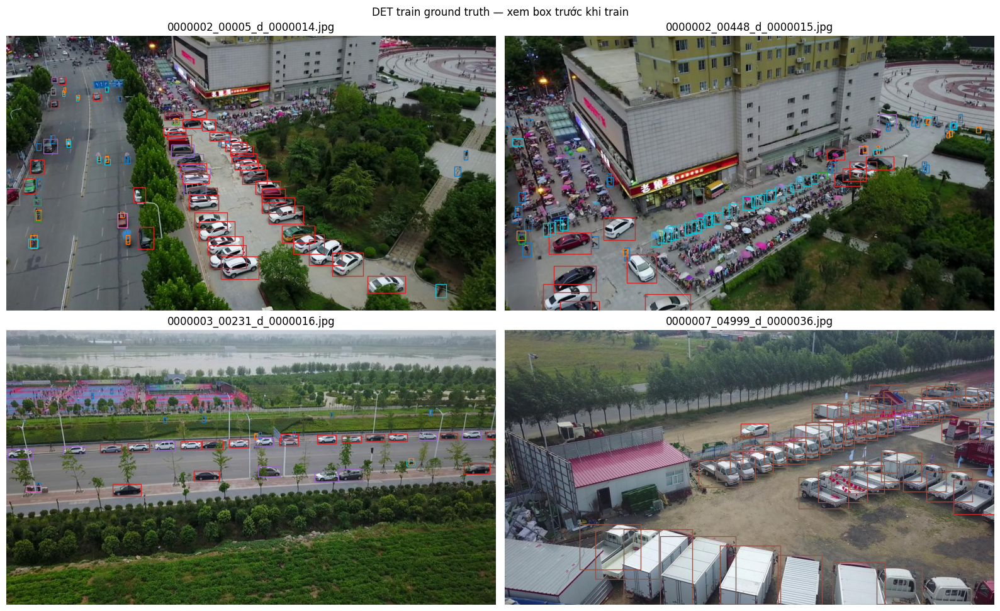

{1: 'pedestrian', 2: 'people', 3: 'bicycle', 4: 'car', 5: 'van', 6: 'truck', 7: 'tricycle', 8: 'awning-tricycle', 9: 'bus', 10: 'motor'}


In [5]:
#@title 5. Xem ảnh và nhãn trước khi train
import matplotlib.pyplot as plt
from PIL import Image
from collections import defaultdict
anns = defaultdict(list)
for ann in train_data['annotations']:
    anns[ann['image_id']].append(ann)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, record in zip(axes.flat, train_data['images'][:4]):
    with Image.open(RAW / record['file_name']) as image:
        ax.imshow(image.convert('RGB'))
    for ann in anns[record['id']]:
        x, y, w, h = ann['bbox']
        color = plt.get_cmap('tab10')(ann['category_id'] - 1)
        ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, edgecolor=color, linewidth=1))
    ax.set_title(Path(record['file_name']).name)
    ax.axis('off')
fig.suptitle('DET train ground truth — xem box trước khi train')
fig.tight_layout()
fig.savefig(RUN_DIR / 'ground_truth_check.png', dpi=150)
plt.show()
print(visdrone.CLASS_NAMES)


## 6. Cấu hình
24 epoch, SGD momentum 0.9, weight decay 1e-4, warm-up 500 iteration,
LR giảm sau 16 và 22 epoch, lật ngang, AMP, seed 0. Giữ batch 4 dù GPU mạnh để bám bảng phân công.
LR tự tính theo batch nếu bạn chủ động thay đổi batch. Fine-tune toàn bộ backbone (5 stages),
đầu phân loại 11 lớp = background + 10 lớp VisDrone. Resize ngắn 800 / dài tối đa 1333.

**Chọn checkpoint:** COCO bbox AP@500 trên DET val, score đầu ra 0.05, NMS 0.5, max output 1000.
Metric 0..1; nhân 100 khi điền bảng %. Không lọc vùng ignored trong metric nội bộ này.
Đánh giá cuối của nhóm cần chạy lại bằng cùng script và cùng quy tắc ignored cho cả ba detector.
Không coi số DET val là số MOT val. Không dùng test-dev để chọn checkpoint.

Lần đầu sẽ tải trọng số COCO chính thức của torchvision qua mạng.


In [6]:
#@title 6. Cấu hình Faster R-CNN
CFG = {
    'epochs': 24,
    'batch_size': 4,
    'eval_batch_size': 4,
    'workers': min(4, os.cpu_count() or 2),
    'min_size': 800,
    'max_size': 1333,
    'amp': True,
    'seed': 0,
}
CFG['lr'] = 0.02 * CFG['batch_size'] / 16
print(json.dumps(CFG, indent=2))
print('Run:', RUN_DIR)
print('Resume:', (RUN_DIR / 'last.pt').exists())


{
  "epochs": 24,
  "batch_size": 4,
  "eval_batch_size": 4,
  "workers": 4,
  "min_size": 800,
  "max_size": 1333,
  "amp": true,
  "seed": 0,
  "lr": 0.005
}
Run: /content/drive/MyDrive/AdvanceCV/runs/T2_frcnn_r50_v2_det_seed0
Resume: False


## 7. Huấn luyện / tiếp tục huấn luyện
Chạy ô dưới bắt đầu train. Loss và tiến độ cập nhật theo batch; mAP cập nhật cuối mỗi epoch.
`best.pt`, `last.pt`, dự đoán val, cấu hình và log được ghi thẳng vào thư mục run trên Drive.

Nếu Colab ngắt: mở lại notebook, giữ nguyên RUN_NAME và cấu hình, chạy lại từ đầu.
Notebook tiếp tục **sau epoch đã lưu hoàn chỉnh**; phần epoch đang chạy khi ngắt sẽ chạy lại.
File `.tmp` không được coi là checkpoint hoàn chỉnh. Không chạy hai phiên vào cùng RUN_NAME.
Không nạp checkpoint từ nguồn không tin cậy (checkpoint resume chứa trạng thái Python).

Không có early stopping: chạy đủ 24 epoch theo Excel. Khi đã đủ 24 epoch, chạy lại ô train
chỉ nạp kết quả. Nếu môi trường torch/torchvision hoặc dữ liệu đổi, notebook yêu cầu run mới
thay vì âm thầm trộn thí nghiệm.


In [7]:
#@title 7. Train 24 epoch hoặc resume tự động
model, history = workflow.train(CFG, RAW, TRAIN_ANN, VAL_ANN, RUN_DIR)
print('Đã hoàn thành:', len(history), 'epoch')
print('Checkpoint tốt nhất:', RUN_DIR / 'best.pt')


Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:00<00:00, 224MB/s]


Epoch 1/24:   0%|          | 0/1604 [00:00<?, ?it/s]

Validation:   0%|          | 0/137 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.12s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.11s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=24.46s).
Accumulating evaluation results...
DONE (t=1.41s).
Saved epoch 1: AP@500=0.2207, AP50=0.3811, 14.1 min. Best=0.2207


Epoch 2/24:   0%|          | 0/1604 [00:00<?, ?it/s]

... (64 outputs left out)

loading annotations into memory...
Done (t=0.11s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.08s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=19.99s).
Accumulating evaluation results...
DONE (t=1.04s).
Saved epoch 23: AP@500=0.2879, AP50=0.4746, 14.9 min. Best=0.2910


Epoch 24/24:   0%|          | 0/1604 [00:00<?, ?it/s]

Validation:   0%|          | 0/137 [00:00<?, ?it/s]

loading annotations into memory...
Done (t=0.12s)
creating index...
index created!
Loading and preparing results...
DONE (t=60.84s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=19.97s).
Accumulating evaluation results...
DONE (t=1.03s).
Saved epoch 24: AP@500=0.2862, AP50=0.4724, 14.9 min. Best=0.2910
Đã hoàn thành: 24 epoch
Checkpoint tốt nhất: /content/drive/MyDrive/AdvanceCV/runs/T2_frcnn_r50_v2_det_seed0/best.pt


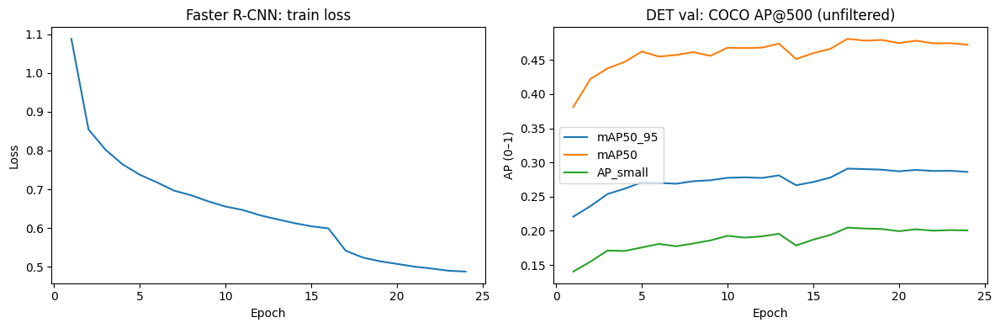

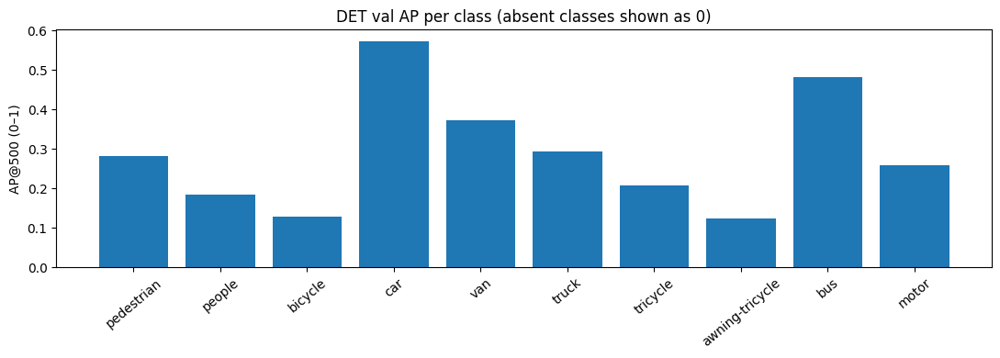

{
  "mAP50_95": 0.29101294033081443,
  "mAP50": 0.48095720192041974,
  "mAP75": 0.3054165584893857,
  "AP_small": 0.2046709452189405,
  "AP_medium": 0.4061262590544502,
  "AP_large": 0.5405902848915578,
  "AR_500": 0.40684078574996735,
  "per_class": {
    "1": 0.2826116993962483,
    "2": 0.1854871956472795,
    "3": 0.12925497439421096,
    "4": 0.5739055445921702,
    "5": 0.37281293051419667,
    "6": 0.294992565588833,
    "7": 0.20797719996394012,
    "8": 0.12388110400425327,
    "9": 0.4812352715773828,
    "10": 0.2579709176296291
  },
  "protocol": "COCO bbox maxDets=[1,100,500]; no ignored-region filtering; fractions 0..1"
}


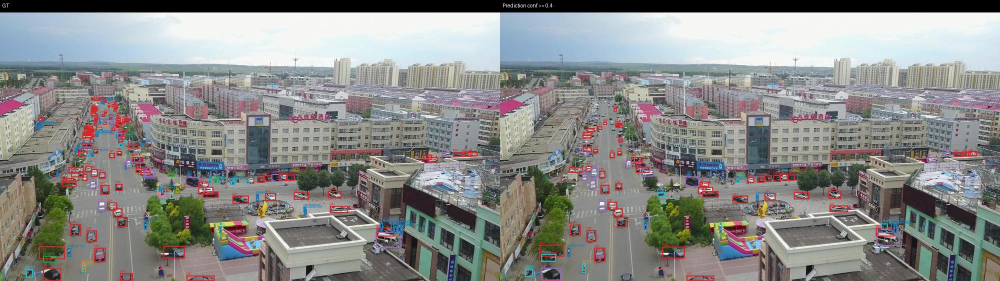

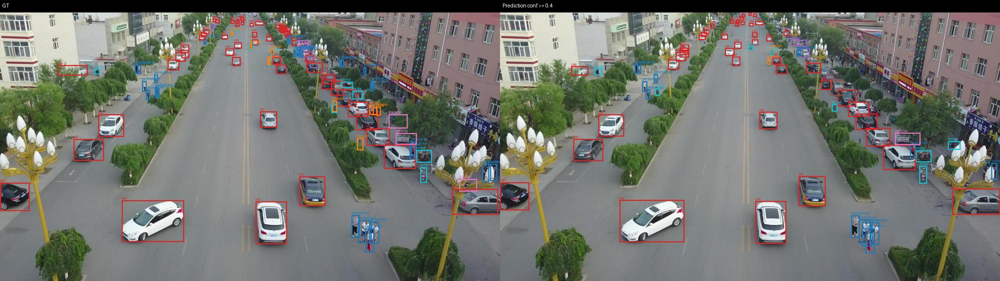

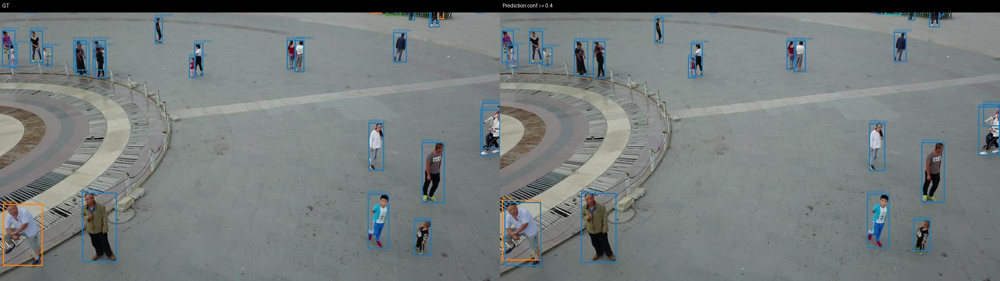

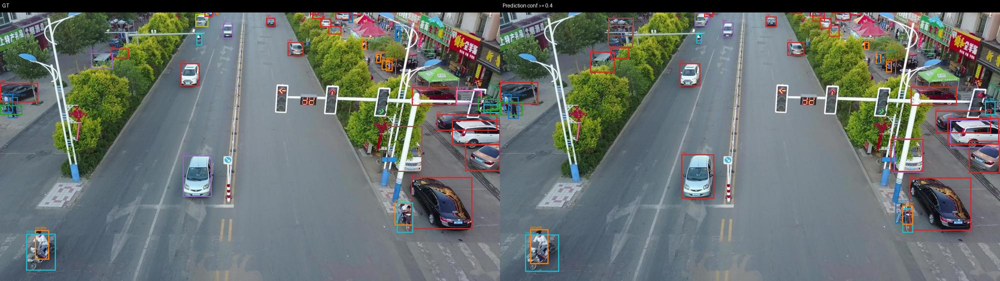

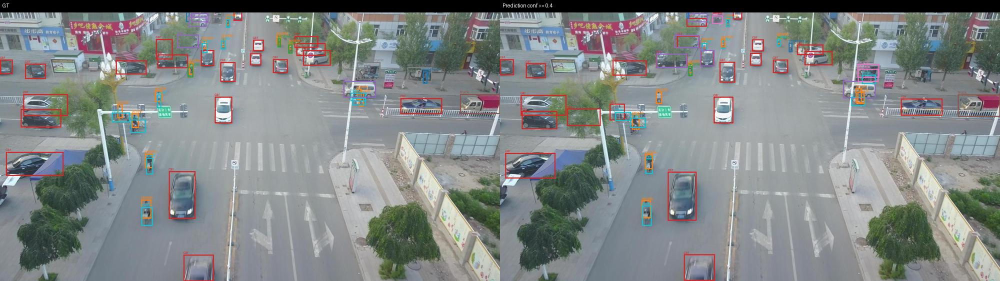

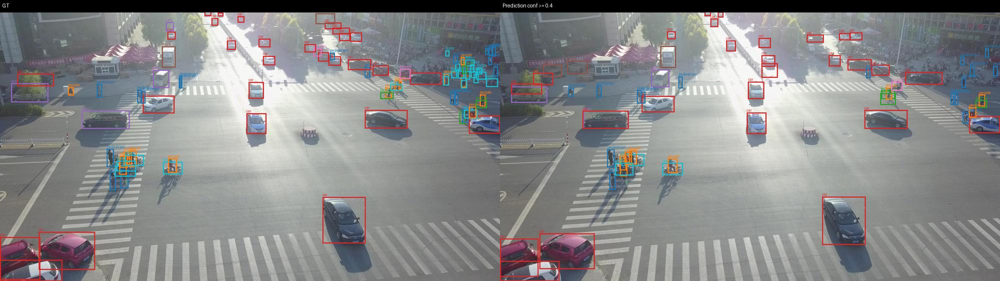

Biểu đồ và ảnh: /content/drive/MyDrive/AdvanceCV/runs/T2_frcnn_r50_v2_det_seed0/figures


In [11]:
#@title 8. Kết quả DET val, đường cong train và ảnh dự đoán
figures = workflow.plot_results(RUN_DIR, VAL_ANN, RAW, visdrone.CLASS_NAMES)
from IPython.display import display
metrics = json.loads((RUN_DIR / 'best_det_val_metrics.json').read_text())
print(json.dumps(metrics, indent=2))
for path in sorted(figures.glob('det_val_*.jpg')):
    display(Image.open(path))
print('Biểu đồ và ảnh:', figures)


## 9. Đánh giá DET test-dev và xuất detection cho tracking trên MOT
**DET test-dev (1.610 ảnh)** dùng đánh giá detection sau khi chốt checkpoint trên DET val.
Bật `EVALUATE_DET_TEST_DEV` ở ô 1 khi sẵn sàng. Nhánh này đọc best.pt, không train thêm,
xuất COCO predictions, metrics JSON và CSV vào `results/detection/DET-test-dev/`.
Nhánh này dùng cùng metric COCO AP@500 chưa lọc ignored như DET val; không thay thế
script đánh giá cuối dùng chung của nhóm. Kết quả đã hoàn tất được dùng lại khi chạy lại ô.

**MOT val / MOT test-dev** phục vụ tracking. Excel chỉ ghi `val` và `test-dev` ở bảng detection;
kế hoạch cũ đánh giá trên MOT. Vì nhóm đã chuyển sang train DET, phải ghi rõ dataset khi ghép bảng:
không ghép mAP DET test-dev của một người với mAP MOT test-dev của người khác.

Mỗi chuỗi có một file 8 cột: `frame,-1,x,y,w,h,score,class`.
Tọa độ ảnh gốc, class VisDrone 1..10 (Faster R-CNN **không cộng 1**), score >=0.05.
Giữ toàn bộ 10 lớp trong cache; runner tracker sẽ chọn 5 lớp tracking.
Frame không có box không có dòng; manifest vẫn ghi đủ số frame và số detection mỗi frame.

Chưa có ZIP MOT val thì notebook vẫn hoàn thành train và báo bỏ qua bước này.
Thêm ZIP rồi chạy lại ô 9 sau. Có thể tiếp tục export theo chuỗi; file dang dở được chạy lại.
Không thay checkpoint trong cùng bộ cache: nếu cần thí nghiệm mới, dùng RUN_NAME mới.

`timing.json` đo 1 lượt có warm-up 50 lần, đồng bộ CUDA, batch 1. Đây là thời gian detector,
**chưa phải FPS detector + ReID + tracker** và chưa phải benchmark 3 lần của nhóm.


In [22]:
#@title Sửa cấu trúc ZIP DET test-dev trước khi chạy cell 9
from pathlib import Path
import zipfile

name = "VisDrone2019-DET-test-dev"
folder = RAW / name
drive_zip = DATASETS / f"{name}.zip"
local_zip = RAW.parent / f"{name}.zip"
archive = local_zip if local_zip.is_file() else drive_zip

assert archive.is_file(), f"Không tìm thấy ZIP: {archive}"

with zipfile.ZipFile(archive) as z:
    paths = {
        p.replace("\\", "/").lstrip("./")
        for p in z.namelist()
    }

has_images = any(p.startswith("images/") for p in paths)
has_labels = any(p.startswith("annotations/") for p in paths)

assert has_images and has_labels, (
    "ZIP không có images/ và annotations/ trực tiếp ở gốc."
)

# ZIP của bạn chứa trực tiếp images/ và annotations/,
# nên phải giải nén VÀO thư mục mang tên bộ dữ liệu.
folder.mkdir(parents=True, exist_ok=True)
workflow.extract_zip(archive, folder)

n_images = len(list((folder / "images").glob("*.jpg")))
n_labels = len(list((folder / "annotations").glob("*.txt")))
assert (n_images, n_labels) == (1610, 1610), (
    f"Chưa đủ dữ liệu: {n_images} ảnh, {n_labels} nhãn"
)

info = drive_zip.stat()
marker = folder / ".colab_extracted.json"
workflow.atomic_json(marker, {
    "zip_bytes": info.st_size,
    "zip_mtime": info.st_mtime,
})

# Kiểm tra ngay bằng chính hàm mà cell 9 sẽ gọi.
ready = workflow.ensure_dataset(DATASETS, RAW, name)
print("ĐÃ SỬA XONG:", ready)
print(f"{n_images} ảnh, {n_labels} nhãn — giờ chạy lại cell 9.")

ĐÃ SỬA XONG: /content/thi_frcnn_visdrone/data/raw/VisDrone2019-DET-test-dev
1610 ảnh, 1610 nhãn — giờ chạy lại cell 9.


In [25]:
#@title 9. Nạp best checkpoint, đánh giá DET test-dev và xuất cache MOT
# Giải phóng model cuối epoch trước khi nạp checkpoint tốt nhất.
if 'model' in globals():
    del model
import gc
gc.collect()
torch.cuda.empty_cache()
best_model, best_state = workflow.load_best(RUN_DIR)
print('Best epoch:', best_state['epoch'] + 1, 'AP:', best_state['best_ap'])
if EVALUATE_DET_TEST_DEV:
    workflow.ensure_dataset(DATASETS, RAW, 'VisDrone2019-DET-test-dev')
    subprocess.run([sys.executable, str(ROOT / 'data/tools/prepare.py'),
                    'coco', 'splits', '--variants', 'det', '--splits', 'test-dev'], check=True)
    test_ann = ROOT / 'data/processed/coco_det/test-dev.json'
    workflow.validate_coco(json.loads(test_ann.read_text()), RAW, expected_images=1610)
    test_out = RUN_DIR / 'results/detection/DET-test-dev'
    test_out.mkdir(parents=True, exist_ok=True)
    test_protocol = {
        'dataset': 'VisDrone2019-DET-test-dev', 'n_images': 1610,
        'checkpoint_sha256': workflow.sha256(RUN_DIR / 'best.pt'),
        'annotation_sha256': workflow.sha256(test_ann),
        'amp': best_state['config']['amp'], 'torch': torch.__version__,
        'torchvision': torchvision.__version__,
        'evaluation': 'COCO bbox AP@500; score>=0.05; no ignored-region filtering; fractions 0..1',
    }
    done_path = test_out / 'completed.json'
    required_outputs = ['predictions.json', 'metrics.json', 'metrics.csv', 'annotations.json']
    if done_path.exists():
        workflow.check_resume_config(json.loads(done_path.read_text()), test_protocol)
        assert all((test_out / name).is_file() for name in required_outputs), 'Thiếu file kết quả test đã lưu.'
        print('Dùng lại kết quả DET test-dev đã hoàn tất; không chạy test lại.')
    else:
        test_dataset = workflow.make_dataset(test_ann, RAW)
        test_predictions = workflow.predict_dataset(
            best_model, test_dataset, CFG['eval_batch_size'], CFG['workers'], best_state['config']['amp'])
        test_metrics = workflow.evaluate_predictions(test_ann, test_predictions)
        test_metrics.update(dataset='VisDrone2019-DET-test-dev', n_images=1610,
                            checkpoint_epoch=best_state['epoch'] + 1)
        workflow.atomic_json(test_out / 'predictions.json', test_predictions)
        workflow.atomic_json(test_out / 'metrics.json', test_metrics)
        import csv
        csv_row = {k: v for k, v in test_metrics.items() if k != 'per_class'}
        with open(test_out / 'metrics.csv.tmp', 'w', newline='', encoding='utf8') as f:
            writer = csv.DictWriter(f, fieldnames=list(csv_row))
            writer.writeheader()
            writer.writerow(csv_row)
        os.replace(test_out / 'metrics.csv.tmp', test_out / 'metrics.csv')
        shutil.copyfile(test_ann, test_out / 'annotations.json')
        workflow.atomic_json(done_path, test_protocol)
        del test_predictions, test_dataset
    print(json.dumps(json.loads((test_out / 'metrics.json').read_text()), indent=2))
    print('DET test-dev:', test_out)
else:
    print('Chưa đánh giá DET test-dev. Bật EVALUATE_DET_TEST_DEV sau khi chốt checkpoint.')
for split, enabled in [('val', EXPORT_MOT_VAL), ('test-dev', EXPORT_MOT_TEST_DEV)]:
    if not enabled:
        print('Không xuất MOT', split, '(chưa bật trong cấu hình).')
        continue
    name = f'VisDrone2019-MOT-{split}'
    if not (DATASETS / f'{name}.zip').is_file():
        print(f'Chưa có {name}.zip. Thêm vào datasets rồi chạy lại ô này; không cần train lại.')
        continue
    workflow.ensure_dataset(DATASETS, RAW, name)
    workflow.export_mot(best_model, RAW, split, RUN_DIR, amp=CFG['amp'])


Best epoch: 17 AP: 0.29101294033081443
Dùng lại kết quả DET test-dev đã hoàn tất; không chạy test lại.
{
  "mAP50_95": 0.21882542055866763,
  "mAP50": 0.37748582112690027,
  "mAP75": 0.2230756741555658,
  "AP_small": 0.11876749953510964,
  "AP_medium": 0.3316380145764226,
  "AP_large": 0.43033903063983253,
  "AR_500": 0.3371153227411542,
  "per_class": {
    "1": 0.15654437972081123,
    "2": 0.06439866172892104,
    "3": 0.08203157548725674,
    "4": 0.46715859418468364,
    "5": 0.3021052862885529,
    "6": 0.30169788524168706,
    "7": 0.12121657185938724,
    "8": 0.12688481947372163,
    "9": 0.4261559031713098,
    "10": 0.14006052843034497
  },
  "protocol": "COCO bbox maxDets=[1,100,500]; no ignored-region filtering; fractions 0..1",
  "dataset": "VisDrone2019-DET-test-dev",
  "n_images": 1610,
  "checkpoint_epoch": 17
}
DET test-dev: /content/drive/MyDrive/AdvanceCV/runs/T2_frcnn_r50_v2_det_seed0/results/detection/DET-test-dev
Already exported: uav0000086_00000_v
Already expor

MOT test-dev/uav0000009_03358_v:   0%|          | 0/219 [00:00<?, ?it/s]

MOT test-dev/uav0000073_00600_v:   0%|          | 0/328 [00:00<?, ?it/s]

MOT test-dev/uav0000073_04464_v:   0%|          | 0/312 [00:00<?, ?it/s]

MOT test-dev/uav0000077_00720_v:   0%|          | 0/780 [00:00<?, ?it/s]

MOT test-dev/uav0000088_00290_v:   0%|          | 0/296 [00:00<?, ?it/s]

... (9 outputs left out)

MOT test-dev/uav0000306_00230_v:   0%|          | 0/420 [00:00<?, ?it/s]

MOT test-dev/uav0000355_00001_v:   0%|          | 0/468 [00:00<?, ?it/s]

MOT test-dev/uav0000370_00001_v:   0%|          | 0/265 [00:00<?, ?it/s]

Exported 6635 frames. Cache ZIP: /content/drive/MyDrive/AdvanceCV/runs/T2_frcnn_r50_v2_det_seed0/results/dets/frcnn_r50/test-dev_cache.zip


In [26]:
#@title 10. Kiểm tra file bàn giao
print('KẾT QUẢ LƯU TRÊN DRIVE:', RUN_DIR)
for name in ['best.pt', 'last.pt', 'run_config.json', 'environment.txt', 'history.csv',
             'best_det_val_metrics.json', 'best_det_val_predictions.json']:
    path = RUN_DIR / name
    print(('OK' if path.exists() else 'CHƯA CÓ'), name)
print('Ảnh:', RUN_DIR / 'figures')
print('Cache cho nhóm:', RUN_DIR / 'results/dets/frcnn_r50')
print('Detection test riêng DET:', RUN_DIR / 'results/detection/DET-test-dev')


KẾT QUẢ LƯU TRÊN DRIVE: /content/drive/MyDrive/AdvanceCV/runs/T2_frcnn_r50_v2_det_seed0
OK best.pt
OK last.pt
OK run_config.json
OK environment.txt
OK history.csv
OK best_det_val_metrics.json
OK best_det_val_predictions.json
Ảnh: /content/drive/MyDrive/AdvanceCV/runs/T2_frcnn_r50_v2_det_seed0/figures
Cache cho nhóm: /content/drive/MyDrive/AdvanceCV/runs/T2_frcnn_r50_v2_det_seed0/results/dets/frcnn_r50
Detection test riêng DET: /content/drive/MyDrive/AdvanceCV/runs/T2_frcnn_r50_v2_det_seed0/results/detection/DET-test-dev


## Đọc kết quả / xử lý lỗi
- **`best.pt`:** mô hình epoch có mAP tốt nhất trên DET val, dùng suy luận.
- **`last.pt`:** trạng thái đầy đủ để train tiếp; không xóa nếu còn cần resume.
- **`history.csv`:** loss và mAP theo epoch, thời gian cả train+val và VRAM.
- **`annotations/`, `source/`, `environment.txt`:** dữ liệu nhãn, code và môi trường của run.
- **`results/dets/frcnn_r50/val_cache.zip`:** gửi cho runner tracker / đánh giá chung.
- **`results/detection/DET-test-dev/metrics.csv`:** chỉ số detection trên DET test-dev,
  thang 0..1. Không dùng thay cho chỉ số MOT test-dev; AP cần nhân 100 khi điền bảng %.
- Không có detection trên một frame là hợp lệ; không chèn box giả.
- **Hết VRAM:** kiểm tra còn model cũ không; restart runtime trước. Nếu đổi batch, dùng run mới.
- **ZIP sai cấu trúc / giải nén ngắt giữa chừng:** sửa ZIP hoặc dùng runtime mới để có ổ tạm sạch;
  checkpoint Drive vẫn được giữ.
- **Thư viện GPU không tương thích:** dùng Colab GPU runtime mới với cặp torch/torchvision có sẵn;
  không nâng cấp riêng một gói. Gửi nguyên traceback nếu vẫn lỗi.

**Việc tiếp theo:** dùng cache với 5 tracker chung; dò ngưỡng trên MOT val; sau khi chốt chạy MOT
test-dev; đánh giá bằng TrackEval của nhóm. Baseline COCO zero-shot cần ánh xạ COCO→VisDrone
thống nhất (không thể coi head 11 lớp mới khởi tạo là zero-shot); notebook này không báo số zero-shot.
